<a href="https://colab.research.google.com/github/olympiasau/A04-clustering/blob/main/PHASE1A4Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [1]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

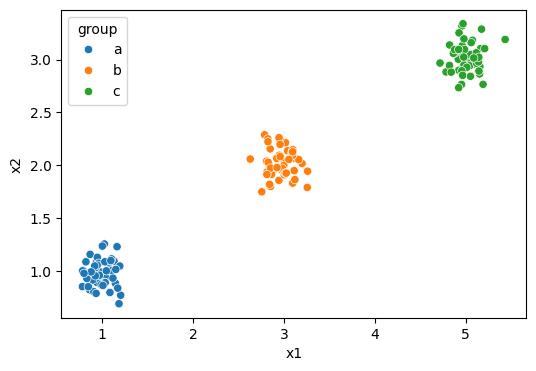

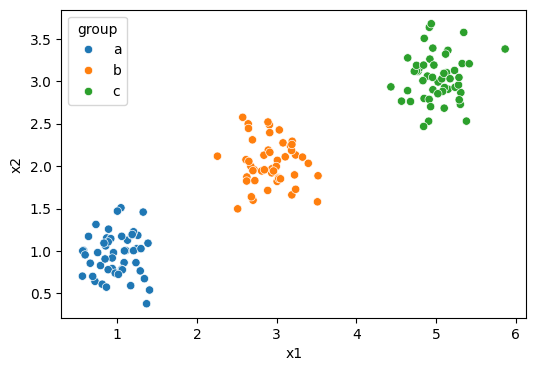

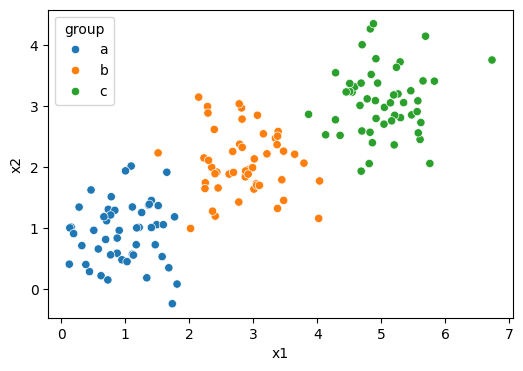

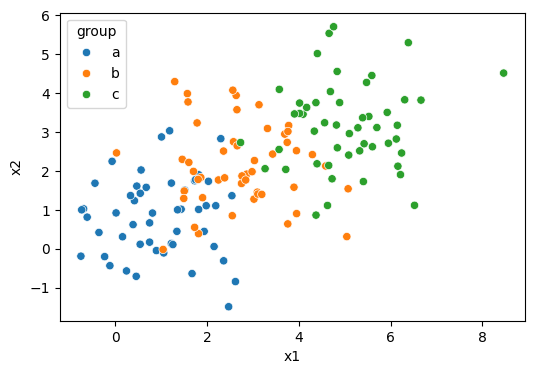

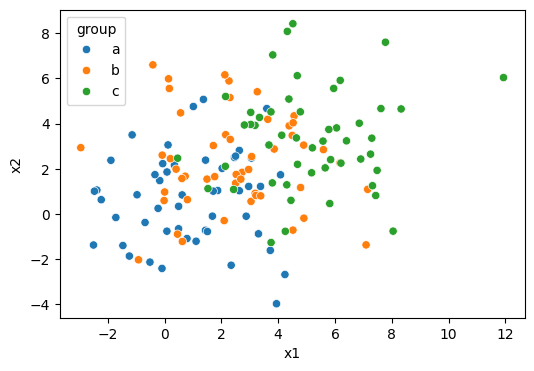

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_125, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_25, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df0_5, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df1_0, x="x1", y="x2", hue="group", ax=ax)
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
scatplot = sns.scatterplot(data=df2_0, x="x1", y="x2", hue="group", ax=ax)
plt.show()

Q1 2.As the noise goes up increases, the visual distinctivness of the clusters becomes less obvious.

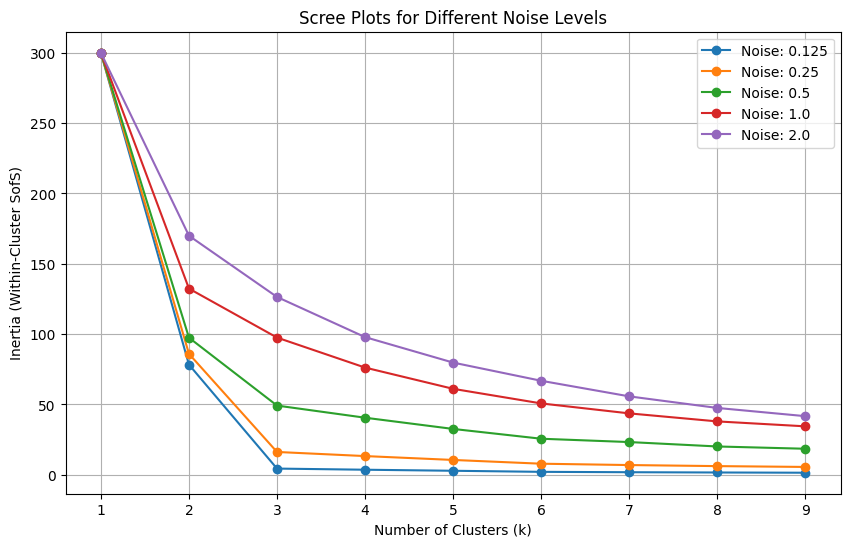

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

k_values = range(1, 10)

plt.figure(figsize=(10, 6))

scaler = StandardScaler()
scaled_0_125 = scaler.fit_transform(df0_125[['x1', 'x2']])
inertias_0_125 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_125)
    inertias_0_125.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_125, marker='o', label='Noise: 0.125')

scaler = StandardScaler()
scaled_0_25 = scaler.fit_transform(df0_25[['x1', 'x2']])
inertias_0_25 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_25)
    inertias_0_25.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_25, marker='o', label='Noise: 0.25')

scaler = StandardScaler()
scaled_0_5 = scaler.fit_transform(df0_5[['x1', 'x2']])
inertias_0_5 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_0_5)
    inertias_0_5.append(kmeans.inertia_)
plt.plot(k_values, inertias_0_5, marker='o', label='Noise: 0.5')

scaler = StandardScaler()
scaled_1_0 = scaler.fit_transform(df1_0[['x1', 'x2']])
inertias_1_0 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_1_0)
    inertias_1_0.append(kmeans.inertia_)
plt.plot(k_values, inertias_1_0, marker='o', label='Noise: 1.0')

scaler = StandardScaler()
scaled_2_0 = scaler.fit_transform(df2_0[['x1', 'x2']])
inertias_2_0 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(scaled_2_0)
    inertias_2_0.append(kmeans.inertia_)
plt.plot(k_values, inertias_2_0, marker='o', label='Noise: 2.0')

plt.title('Scree Plots for Different Noise Levels')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SofS)')
plt.xticks(range(1, 10))
plt.legend()
plt.grid(True)
plt.show()

Q1 3. At low noise (0.125-0.25), the clusters are tight and well separated, so inertia drops steeply until k=3 and then flattens, giving a sharp elbow and a clear choice of k=3.With moderate noise (0.5-1.0), the elbow loosens into a gradual bend that still turns at k=3, so choosing k takes more judgment. At noise = 2.0, the clusters overlap and the curve is smooth with no clear corner, so no k can be definitively selected.

Q1 4. The elbow shows where adding more clusters stops being worth it; inertia always decreases as k increases, but it drops substantially only when a new cluster center is finding a real group in the data. In the low-noise plots (0.125, 0.25), inertia falls from about 300 to almost 0 by k=3 because each center gets its own tight group, and after that extra centers split groups that are already tight, so the line bends at k=3 and then flattens out. As noise grows (1.0,2.0), the groups combine/blur together and there is no real difference between finding a group and cutting up noise, so each new center helps by a small, gradual amount and the elbow fades away.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

In [4]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna()

print(df.shape)
print(df.dtypes)
print(df['Country'].duplicated().sum())
print(df['Country'].tolist())
print(df.describe())

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
0
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 

In [5]:
df = df.drop(columns=['index', 'Year']).reset_index(drop=True)

Q2 1. The data has 148 countries with no missing values, duplicate countries, or type problems, but the "index" and "Year" (always 2020) dont have information, so they should be dropped. The four numeric variables are on different scales, so they need to be min-max normalized; otherwise, when calculating k means, the dollar columns would dominate the distances.

In [6]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']

for c in cols:
    df[c + ' (norm)'] = minmax(df[c])

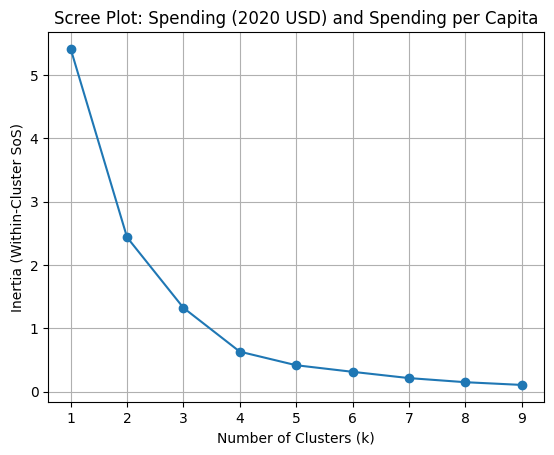

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

X1 = df[['Spending (2020 USD) (norm)', 'Spending per Capita (norm)']]

inertias = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X1)
    inertias.append(km.inertia_)

plt.plot(range(1, 10), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: Spending (2020 USD) and Spending per Capita')
plt.grid(True)
plt.show()

Q2 2.The scree plot decreases steeply from k=1 to k=3 and then flattens out. The elbow is around k=3, so I chose this as the number of clusters.

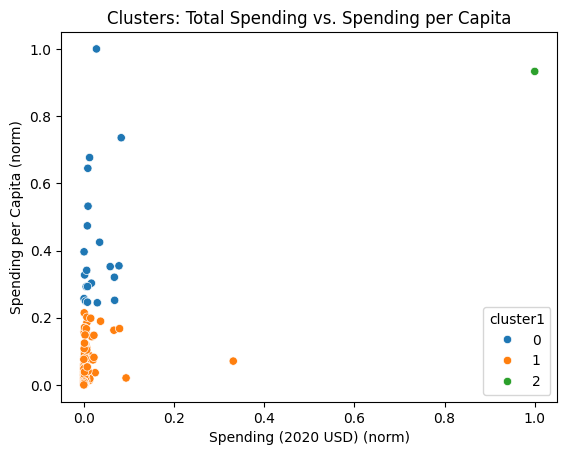

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster1                                                                   
0                       21.0   19975.991473  21749.736747     405.790494   
1                      126.0    5943.346303  24858.961064       8.622460   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster1                                                               
0           4980.428135    7269.880030   27300.894701   64558.400000   
1            162.761743     580.758315    3225.333414  257973.429834   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

In [8]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X1)
df['cluster1'] = km.labels_

sns.scatterplot(data=df, x='Spending (2020 USD) (norm)', y='Spending per Capita (norm)',
                hue='cluster1', palette='tab10')
plt.title('Clusters: Total Spending vs. Spending per Capita')
plt.show()

# Describe table by cluster (real units)
print(df.groupby('cluster1')[['Spending (2020 USD)', 'Spending per Capita']].describe())

# Where is the United States?
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'Spending (2020 USD)', 'Spending per Capita', 'cluster1']])

# Countries in each cluster
for c in sorted(df['cluster1'].unique()):
    print(c, df.loc[df['cluster1'] == c, 'Country'].tolist())

Q2 2. The United States is alone in cluster two because its total spending, which is about 778 billion dollars, surpassed every other country so much that it sits at 1.0 on the normalized scale while almost all other countries are near 0. The other two clusters split mostly by spending per capita: cluster zero, which includes 21 countries, averages about 1,046 dollars per person, while cluster one, which includes 126 countries, averages about 122 dollars per person. This implies cluster zero is mostly wealthier and high-income countries that spend more per person, while cluster one includes both smaller spenders and large total spenders.

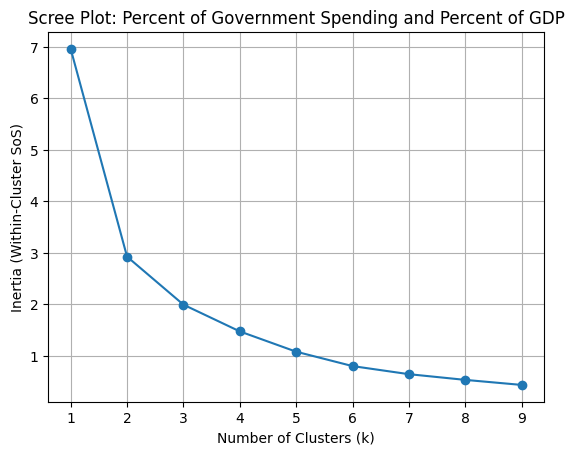

In [9]:
X2 = df[['Percent of Government Spending (norm)', 'Percent of GDP (norm)']]

inertias2 = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2)
    inertias2.append(km.inertia_)

plt.plot(range(1, 10), inertias2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: Percent of Government Spending and Percent of GDP')
plt.grid(True)
plt.show()

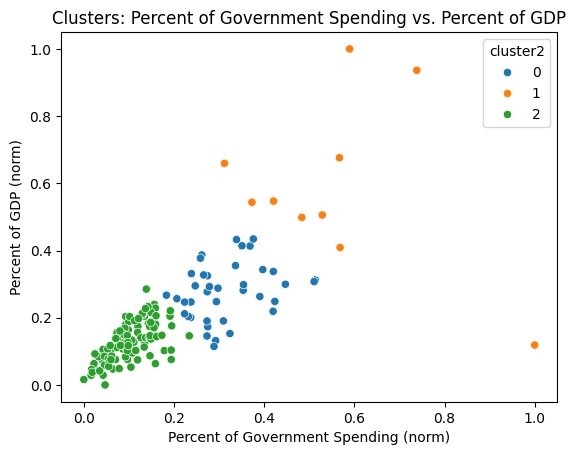

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       mi

In [10]:
k = 3

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X2)
df['cluster2'] = km.labels_

sns.scatterplot(data=df, x='Percent of Government Spending (norm)', y='Percent of GDP (norm)',
                hue='cluster2', palette='tab10')
plt.title('Clusters: Percent of Government Spending vs. Percent of GDP')
plt.show()

print(df.groupby('cluster2')[['Percent of Government Spending', 'Percent of GDP']].describe())

print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'Percent of Government Spending', 'Percent of GDP', 'cluster2']])

for c in sorted(df['cluster2'].unique()):
    print(c, df.loc[df['cluster2'] == c, 'Country'].tolist())

Q2 3. For this part the clusters split by how much of the economy and government budget goes to the military: cluster two with 99 countries is low, with about 3.6% of government spending and 1.3% of GDP, cluster zero with 39 countries is moderate at about 9.9% and 2.7%, and cluster one with 10 countries is high at about 17.1% and 5.8%. The United States is in the moderate cluster zero because while the military is large in dollars, it is an ordinary share of its economy and budget. Contrary to part one where the US stood out more substantially due to its size, putting things in perspective with ratios/percentages made it easier to compare. With this part separating countries by military burden, many wealthy countries like Australia are now in the low cluster, while countries like Algeria and Pakistan that were in the low spending per person in part one are now in the high-burden cluster.


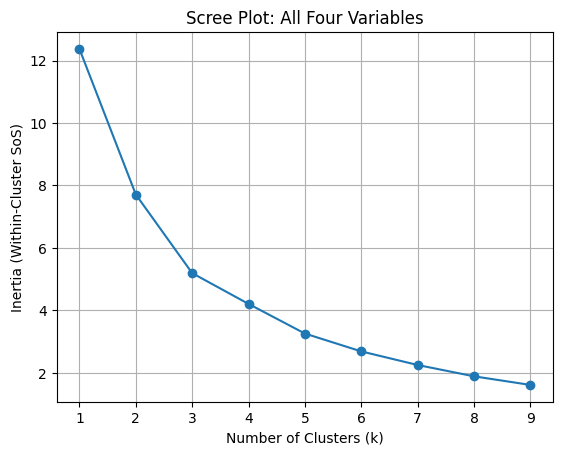

In [11]:
X3 = df[['Spending (2020 USD) (norm)', 'Spending per Capita (norm)',
         'Percent of Government Spending (norm)', 'Percent of GDP (norm)']]

inertias3 = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X3)
    inertias3.append(km.inertia_)

plt.plot(range(1, 10), inertias3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster SoS)')
plt.title('Scree Plot: All Four Variables')
plt.grid(True)
plt.show()

In [12]:
k = 4

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X3)
df['cluster3'] = km.labels_

# Describe table in real units
print(df.groupby('cluster3')[['Spending (2020 USD)', 'Spending per Capita',
                              'Percent of Government Spending', 'Percent of GDP']].mean())
print(df['cluster3'].value_counts().sort_index())

# Where is the US?
print(df.loc[df['Country'] == 'United States of America',
             ['Country', 'cluster1', 'cluster2', 'cluster3']])

# Countries in each cluster
for c in sorted(df['cluster3'].unique()):
    print(c, df.loc[df['cluster3'] == c, 'Country'].tolist())

# How do the new clusters line up with parts 1 and 2?
print(pd.crosstab(df['cluster3'], df['cluster1']))
print(pd.crosstab(df['cluster3'], df['cluster2']))

          Spending (2020 USD)  Spending per Capita  \
cluster3                                             
0                 4513.543790            70.290644   
1               147964.582042          1875.150751   
2                 9073.543709           215.920971   
3                15330.618681           612.677541   

          Percent of Government Spending  Percent of GDP  
cluster3                                                  
0                               0.043199        0.012481  
1                               0.135351        0.062634  
2                               0.123701        0.034105  
3                               0.033280        0.016585  
cluster3
0    86
1     6
2    30
3    26
Name: count, dtype: int64
                      Country  cluster1  cluster2  cluster3
144  United States of America         2         0         1
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Bangladesh', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'B

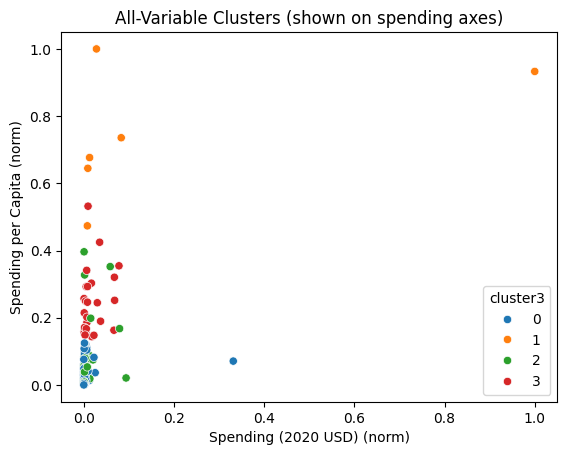

In [13]:
sns.scatterplot(data=df, x='Spending (2020 USD) (norm)', y='Spending per Capita (norm)',
                hue='cluster3', palette='tab10')
plt.title('All-Variable Clusters (shown on spending axes)')
plt.show()

Q2 4. Using all four variables with k=4, the clusters combine both size and burden: cluster zero (86 countries) is low on everything, cluster one (6 countries: the US, Israel, Kuwait, Oman, Saudi Arabia, and Singapore) is high on everything, cluster two (30 countries such as Algeria, Armenia, and Belarus) has a high share of government spending and GDP but modest dollar totals, and cluster three (26 countries such as Australia, Austria, Canada, and Denmark) is wealthy with a low military burden. The results are closer to part two, since the clusters line up well with the burden groups, but the dollar variables split the low-burden countries into poorer and wealthier groups, which part two could not do. The United States is no longer alone like in part one, and is instead grouped with other countries that spend heavily in dollars, per person, and as a share of their economy.

Q2 5. k means found useful patterns, particularly in part two. Using the ratios (% of government spending and % of GDP) showed where countries were actually putting their money, because it compares military priority on an equal footing instead of just dollar amount. Part one was interesting but mostly reflected general global wealth, with the US standing out because of its massive size and wealthier countries grouping together by spending per person. Using all four variables in part three combined both views and split the low-burden countries into poorer and wealthier groups, which neither earlier part could do on its own. Overall k-means clustering was a great way in visualizing the relationships between government spending across the world.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Olympia Sauerwein

**Date:** 10/12

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [14]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]